# Практическое занятие №3-4. Бинарная классификация вина (логистическая регрессия)

**Задание.** Загрузить `winequality-red.csv`. Последний столбец — качество вина; хорошим считается вино с оценкой 7 и выше, остальное — некачественным. Классифицировать вино на два класса и получить уравнение гиперповерхности в пространстве признаков, отделяющей один класс от другого.

In [1]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

## Загрузка выборки

Файл взят из UCI Machine Learning Repository (Wine Quality), разделитель — `;`.

In [2]:
dataset = pd.read_csv('winequality-red.csv', sep=';')
print('Размер выборки составляет l={} объектов.'.format(len(dataset)))
dataset.sample(5, random_state=0)

Размер выборки составляет l=1599 объектов.


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1109,10.8,0.470,0.43,2.10,0.171,27.0,66.0,0.99820,3.17,0.76,10.8,6
1032,8.1,0.820,0.00,4.10,0.095,5.0,14.0,0.99854,3.36,0.53,9.6,5
1002,9.1,0.290,0.33,2.05,0.063,13.0,27.0,0.99516,3.26,0.84,11.7,7
487,10.2,0.645,0.36,1.80,0.053,5.0,14.0,0.99820,3.17,0.42,10.0,6
979,12.2,0.450,0.49,1.40,0.075,3.0,6.0,0.99690,3.13,0.63,10.4,5


## Начало работы с данными

**Множество объектов.** Объекты описываются $n = 11$ вещественными признаками (физико-химические показатели): fixed acidity, volatile acidity, citric acid, residual sugar, chlorides, free sulfur dioxide, total sulfur dioxide, density, pH, sulphates, alcohol. То есть $\mathbf{X} \in \mathbb{R}^{l \times n}$.

**Множество ответов.** Исходно `quality` — целое число от 3 до 8. По условию переходим к двум классам: «Хорошее» (`quality ≥ 7`) и «Некачественное».

**Тип задачи** — бинарная классификация.

In [3]:
dataset.info()
print('Пропусков:', dataset.isna().sum().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB
Пропусков: 0


In [4]:
dataset['quality'].value_counts().sort_index()

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

Классы закодируем числами $-1$ (некачественное) и $1$ (хорошее), как в примере с ирисами.

In [5]:
dataset['класс'] = np.where(dataset['quality'] >= 7, 1, -1)
features = dataset.columns.drop(['quality', 'класс'])
print(dataset['класс'].value_counts())
print('Доля хорошего вина: {:.1%}'.format((dataset['класс'] == 1).mean()))

класс
-1    1382
 1     217
Name: count, dtype: int64
Доля хорошего вина: 13.6%


Классы несбалансированы: хорошего вина ~14 %. Поэтому одной accuracy недостаточно — модель «всё некачественное» уже даёт ~86 %. Смотрим также precision/recall по классу «Хорошее».

## Анализ данных

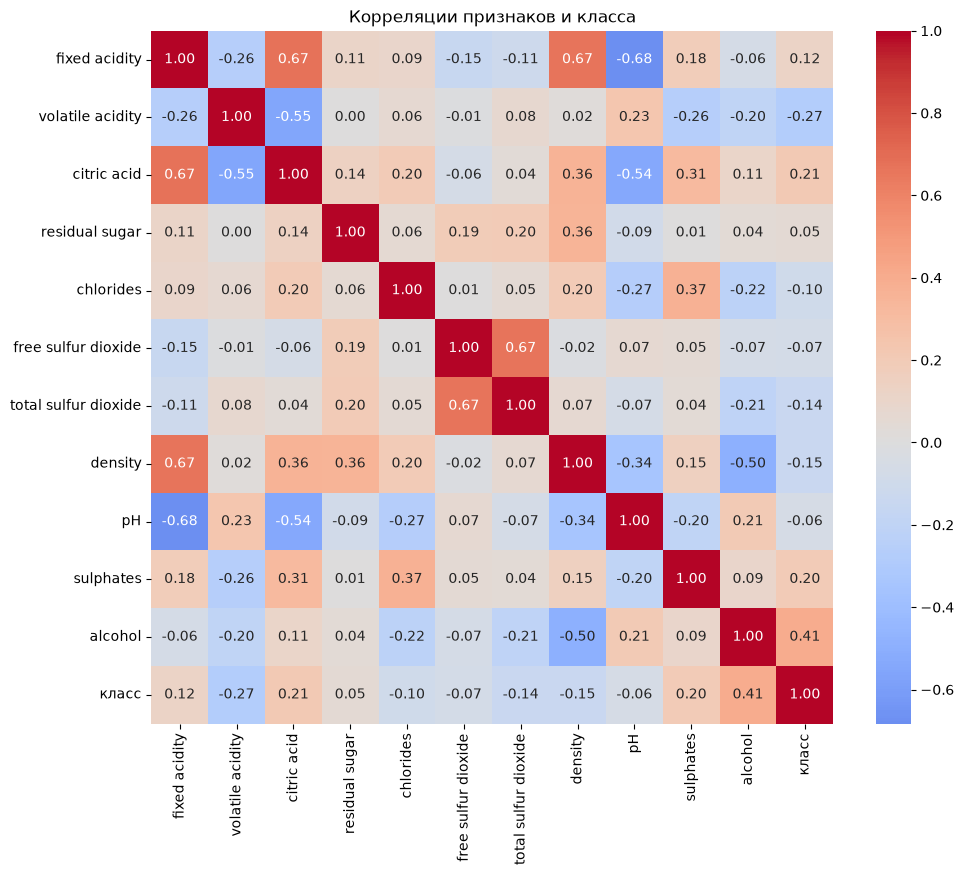

In [6]:
plt.figure(figsize=(11, 9))
sns.heatmap(dataset.drop(columns='quality').corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Корреляции признаков и класса')
plt.show()

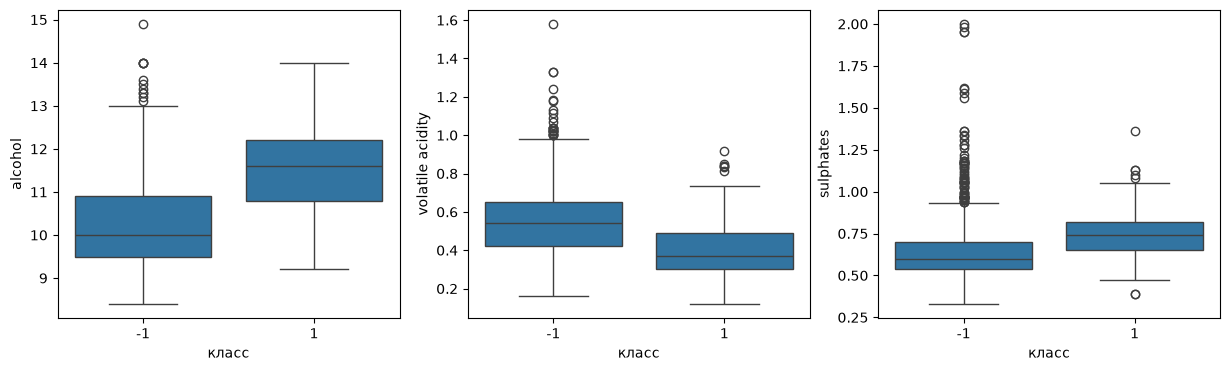

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['alcohol', 'volatile acidity', 'sulphates']):
    sns.boxplot(data=dataset, x='класс', y=col, ax=ax)
plt.show()

Сильнее всего с классом связаны `alcohol` (0.41, больше — лучше), `volatile acidity` (−0.27, больше — хуже), затем `citric acid` (0.22) и `sulphates` (0.20). Полностью классы по одному признаку не разделяются, нужна комбинация признаков.

## Построение модели

Модель — линейный классификатор $f(\theta, \mathbf{x}) = \mathrm{sign}(\theta^\top \mathbf{x})$, параметры ищем логистической регрессией. Как в примере, добавляем признак-константу 1, тогда последняя компонента $\theta$ — свободный член.

Признаки имеют разный масштаб (density ≈ 1, total sulfur dioxide до ~290), поэтому для обучения стандартизуем их, а итоговое уравнение переведём обратно в исходные единицы. Для честной оценки качества отложим 25 % выборки в тест.

`LogisticRegression` по умолчанию использует L2-регуляризацию (`C=1`); так как свободный член задан столбцом единиц, штрафуется и он. На этих данных это слабо сдвигает коэффициенты и не меняет точность.

In [8]:
X_raw = dataset[features].values
y = dataset['класс'].values

X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.25, random_state=0, stratify=y)

scaler = StandardScaler().fit(X_train)

def add_ones(X):
    return np.array(np.hstack([X, np.ones([len(X), 1])]), dtype=np.float64)

X_train_s = add_ones(scaler.transform(X_train))
X_test_s = add_ones(scaler.transform(X_test))

model = LogisticRegression(random_state=0, max_iter=2000, fit_intercept=False)
_ = model.fit(X_train_s, y_train)
model.coef_

array([[ 0.65361754, -0.43189808,  0.15681378,  0.39170771, -0.33461004,
         0.03527995, -0.37314156, -0.60216476,  0.02362051,  0.61036506,
         0.93116963, -2.90726418]])

## Качество классификации

In [9]:
for name, Xs, ys in [('train', X_train_s, y_train), ('test', X_test_s, y_test)]:
    print(f'Accuracy ({name}): {accuracy_score(ys, model.predict(Xs)):.3f}')
print('Accuracy константной модели «всё некачественное» (test): {:.3f}'.format((y_test == -1).mean()))
print()
print(classification_report(y_test, model.predict(X_test_s), target_names=['Некачественное', 'Хорошее']))

Accuracy (train): 0.889
Accuracy (test): 0.845
Accuracy константной модели «всё некачественное» (test): 0.865

                precision    recall  f1-score   support

Некачественное       0.90      0.92      0.91       346
       Хорошее       0.41      0.33      0.37        54

      accuracy                           0.84       400
     macro avg       0.65      0.63      0.64       400
  weighted avg       0.83      0.84      0.84       400



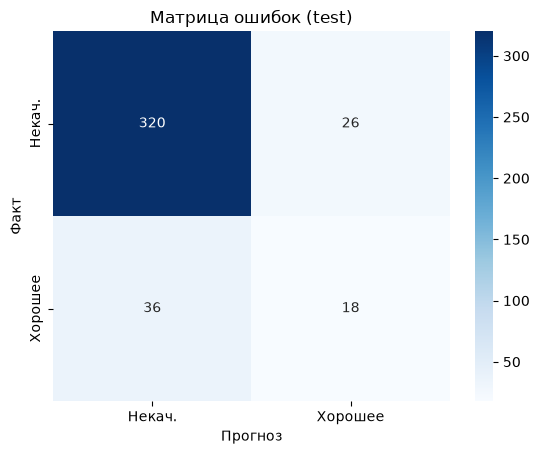

In [10]:
cm = confusion_matrix(y_test, model.predict(X_test_s))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Некач.', 'Хорошее'], yticklabels=['Некач.', 'Хорошее'])
plt.xlabel('Прогноз')
plt.ylabel('Факт')
plt.title('Матрица ошибок (test)')
plt.show()

Модель находит только треть хорошего вина: из-за дисбаланса ей выгоднее почти всегда отвечать «Некачественное». Для сравнения обучим ту же модель с балансировкой классов (`class_weight='balanced'` — ошибки на редком классе весят больше).

In [11]:
model_bal = LogisticRegression(random_state=0, max_iter=2000, fit_intercept=False, class_weight='balanced')
_ = model_bal.fit(X_train_s, y_train)
print(f'Accuracy (test): {accuracy_score(y_test, model_bal.predict(X_test_s)):.3f}')
print(classification_report(y_test, model_bal.predict(X_test_s), target_names=['Некачественное', 'Хорошее']))

Accuracy (test): 0.772
                precision    recall  f1-score   support

Некачественное       0.94      0.79      0.86       346
       Хорошее       0.33      0.69      0.45        54

      accuracy                           0.77       400
     macro avg       0.64      0.74      0.65       400
  weighted avg       0.86      0.77      0.80       400



## Уравнение разделяющей гиперплоскости

В стандартизованных признаках $z_j = (x_j - \mu_j)/\sigma_j$ гиперплоскость: $\sum_j \theta_j z_j + \theta_0 = 0$. Подставляя $z_j$, получаем уравнение в исходных признаках:

$$\sum_j w_j x_j + w_0 = 0, \qquad w_j = \frac{\theta_j}{\sigma_j}, \qquad w_0 = \theta_0 - \sum_j \frac{\theta_j \mu_j}{\sigma_j}$$

Если $\sum_j w_j x_j + w_0 > 0$ — вино «Хорошее», иначе «Некачественное».

In [12]:
theta = model.coef_[0]
w = theta[:-1] / scaler.scale_
w0 = theta[-1] - np.sum(theta[:-1] * scaler.mean_ / scaler.scale_)

pd.DataFrame({'θ (станд. признаки)': theta[:-1], 'w (исходные признаки)': w}, index=features)

,θ (станд. признаки),w (исходные признаки)
fixed acidity,0.653618,0.366285
volatile acidity,-0.431898,-2.447329
citric acid,0.156814,0.807912
residual sugar,0.391708,0.286708
chlorides,-0.334610,-7.242624
free sulfur dioxide,0.035280,0.003434
total sulfur dioxide,-0.373142,-0.011312
density,-0.602165,-319.947844
pH,0.023621,0.149057
sulphates,0.610365,3.753314


In [13]:
def hyperplane(model):
    theta = model.coef_[0]
    w = theta[:-1] / scaler.scale_
    w0 = theta[-1] - np.sum(theta[:-1] * scaler.mean_ / scaler.scale_)
    return w, w0

for name, m in [('Разделяющая гиперплоскость', model), ('Разделяющая гиперплоскость (balanced)', model_bal)]:
    w_m, w0_m = hyperplane(m)
    terms = ' '.join(f'{c:+.4f}·[{f}]' for c, f in zip(w_m, features))
    print(name + ':')
    print(f'{terms} {w0_m:+.4f} = 0\n')

Разделяющая гиперплоскость:
+0.3663·[fixed acidity] -2.4473·[volatile acidity] +0.8079·[citric acid] +0.2867·[residual sugar] -7.2426·[chlorides] +0.0034·[free sulfur dioxide] -0.0113·[total sulfur dioxide] -319.9478·[density] +0.1491·[pH] +3.7533·[sulphates] +0.8877·[alcohol] +302.1983 = 0

Разделяющая гиперплоскость (balanced):
+0.4464·[fixed acidity] -2.9980·[volatile acidity] -0.0472·[citric acid] +0.3361·[residual sugar] -6.1348·[chlorides] +0.0064·[free sulfur dioxide] -0.0127·[total sulfur dioxide] -313.9443·[density] +0.3515·[pH] +4.0103·[sulphates] +1.0628·[alcohol] +294.8723 = 0



Проверим, что уравнение в исходных единицах даёт те же прогнозы, что и модель:

In [14]:
pred_eq = np.where(X_test @ w + w0 > 0, 1, -1)
print('Совпадение с model.predict:', (pred_eq == model.predict(X_test_s)).mean())

Совпадение с model.predict: 1.0


## Классификация неизвестных вин и итоговые метрики

По заданию обученную модель нужно применить к винам, которых она не видела. Это 400 вин отложенной тестовой выборки: в обучении (в том числе при подборе параметров стандартизации) они не участвовали. Для каждого вина считаем значение $\sum_j w_j x_j + w_0$ из уравнения гиперплоскости в исходных единицах, вероятность класса «Хорошее» и итоговый класс.

In [15]:
def classify_wine(X_new, w=w, w0=w0):
    """X_new: массив (m, 11) с признаками в исходных единицах, порядок как в features."""
    score = X_new @ w + w0
    proba = 1 / (1 + np.exp(-score))
    return score, proba, np.where(score > 0, 'Хорошее', 'Не качественное')

rng = np.random.RandomState(1)
idx = np.concatenate([rng.choice(np.where(y_test == 1)[0], 4, replace=False),
                      rng.choice(np.where(y_test == -1)[0], 4, replace=False)])
score, proba, label = classify_wine(X_test[idx])
unknown = pd.DataFrame(X_test[idx][:, [10, 1, 9]], columns=['alcohol', 'volatile acidity', 'sulphates'])
unknown['score'] = score.round(2)
unknown['P(хорошее)'] = proba.round(3)
unknown['прогноз'] = label
unknown['факт'] = np.where(y_test[idx] == 1, 'Хорошее', 'Не качественное')
unknown['верно'] = unknown['прогноз'] == unknown['факт']
unknown

,alcohol,volatile acidity,sulphates,score,P(хорошее),прогноз,факт,верно
0,11.9,0.120,0.76,0.71,0.670,Хорошее,Хорошее,True
1,11.8,0.180,0.76,-0.17,0.457,Не качественное,Хорошее,False
2,13.3,0.410,0.79,1.90,0.870,Хорошее,Хорошее,True
3,12.9,0.585,0.94,-0.20,0.449,Не качественное,Хорошее,False
4,9.9,1.040,0.55,-4.98,0.007,Не качественное,Не качественное,True
5,12.5,0.270,0.53,0.70,0.669,Хорошее,Не качественное,False
6,12.1,0.600,0.51,-1.57,0.173,Не качественное,Не качественное,True
7,9.8,0.490,1.98,0.24,0.559,Хорошее,Не качественное,False


Новое вино можно задать вручную: ниже гипотетический образец с высоким содержанием алкоголя и сульфатов и низкой летучей кислотностью (остальные признаки — медианы по обучающей выборке). Даже такое «хорошее на вид» вино модель оценивает почти на границе классов (вероятность около 0.49), то есть класс определяется с низкой уверенностью: хорошее вино по этим признакам отделяется от остального плохо.

In [16]:
new_wine = pd.Series(np.median(X_train, axis=0), index=features)
new_wine[['alcohol', 'sulphates', 'volatile acidity']] = [12.5, 0.85, 0.35]
score, proba, label = classify_wine(new_wine.values.reshape(1, -1))
print(f'score = {score[0]:+.3f}, P(хорошее) = {proba[0]:.3f} -> {label[0]}')

score = -0.022, P(хорошее) = 0.494 -> Не качественное


Итоговые метрики на тестовой выборке для обеих моделей (класс «Хорошее» считаем положительным). Precision — доля действительно хороших среди предсказанных хорошими, Recall — доля найденных хороших среди всех хороших.

In [17]:
from sklearn.metrics import precision_score, recall_score, f1_score

rows = {}
for name, m in [('обычная', model), ('balanced', model_bal)]:
    pred = m.predict(X_test_s)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[-1, 1]).ravel()
    rows[name] = {'Accuracy': accuracy_score(y_test, pred),
                  'Precision': precision_score(y_test, pred, pos_label=1),
                  'Recall': recall_score(y_test, pred, pos_label=1),
                  'F1': f1_score(y_test, pred, pos_label=1),
                  'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp}
pd.DataFrame(rows).T.round(3)

,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
обычная,0.845,0.409,0.333,0.367,320.0,26.0,36.0,18.0
balanced,0.772,0.333,0.685,0.448,272.0,74.0,17.0,37.0


### Выводы

1. Задача сведена к бинарной классификации (quality ≥ 7 → «Хорошее»), классы несбалансированы (~14 % хорошего вина).
2. Логистическая регрессия даёт линейную разделяющую гиперплоскость в 11-мерном пространстве признаков; её уравнение выписано выше в исходных единицах.
3. По стандартизованным коэффициентам $\theta$ сильнее всего к «Хорошему» тянут `alcohol`, `fixed acidity` и `sulphates`, к «Некачественному» — `density`, `volatile acidity`, `total sulfur dioxide`. Коэффициенты $w$ в исходных единицах сравнивать по модулю нельзя: они зависят от масштаба признака (у `density` −320 только потому, что плотность меняется в третьем знаке). Трактовать $\theta$ по отдельности тоже надо осторожно: признаки коррелируют между собой (например, `fixed acidity` с `density` и `citric acid`), и вес делится между ними — у `fixed acidity` корреляция с классом всего 0.12, а коэффициент второй по величине.
4. Accuracy на тесте (0.845) даже ниже константной модели (0.865), recall класса «Хорошее» — 0.33. Линейная граница по умолчанию плохо работает при дисбалансе классов. С `class_weight='balanced'` recall «Хорошего» растёт до 0.69, но precision падает до 0.33 и accuracy — до 0.77 (больше ложных срабатываний). Какую из двух гиперплоскостей выбрать, зависит от того, что важнее: не пропустить хорошее вино или не ошибиться в нём.
5. В датасете 240 точных дубликатов строк, и для 94 из 400 тестовых вин в обучающей выборке есть копия. Для линейной модели это почти не влияет на оценку: на 306 тестовых винах без копий accuracy 0.850, recall 0.351, F1 0.361 (против 0.845, 0.333 и 0.367 на всём тесте; проверено отдельным расчётом на том же разбиении).